In [1]:
# ==========================================================
# Stage 6 – Step 1.1 : Imports
# ==========================================================

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision.models as models
import timm

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

from tqdm.auto import tqdm

print("=" * 70)
print("Stage 6 - Performance Evaluation")
print("=" * 70)

print("PyTorch :", torch.__version__)
print("OpenCV  :", cv2.__version__)
print("timm    :", timm.__version__)

Stage 6 - Performance Evaluation
PyTorch : 2.10.0
OpenCV  : 4.13.0
timm    : 1.0.25


In [2]:
# ==========================================================
# Stage 6 – Step 1.2 : Device Configuration
# ==========================================================

if torch.backends.mps.is_available():
    device = torch.device("mps")
    device_name = "Apple Silicon GPU (MPS)"

elif torch.cuda.is_available():
    device = torch.device("cuda")
    device_name = torch.cuda.get_device_name(0)

else:
    device = torch.device("cpu")
    device_name = "CPU"


print("=" * 70)
print("Device Configuration")
print("=" * 70)

print("Device      :", device)
print("Description :", device_name)

Device Configuration
Device      : mps
Description : Apple Silicon GPU (MPS)


In [3]:
# ==========================================================
# Stage 6 – Step 1.3 : Project Paths
# ==========================================================

project_root = (
    Path.home()
    / "Desktop"
    / "Mtech_final_project"
    / "SegFusionFormer"
)

dataset_dir = project_root / "dataset"

images_dir = dataset_dir / "images"
lung_masks_dir = dataset_dir / "lung_masks"

models_dir = project_root / "models"
outputs_dir = project_root / "outputs"
results_dir = project_root / "results"

tables_dir = results_dir / "tables"
figures_dir = results_dir / "figures"

evaluation_dir = figures_dir / "evaluation"

evaluation_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Important files
classifier_path = (
    models_dir
    / "best_segfusionformer.pth"
)

unet_path = (
    models_dir
    / "best_unet.pth"
)

csv_path = (
    dataset_dir
    / "Data_Entry_2017.csv"
)

threshold_path = (
    tables_dir
    / "optimal_thresholds.csv"
)

print("=" * 70)
print("Stage 6 Paths")
print("=" * 70)

print("Project Root :", project_root)
print("Images       :", images_dir)
print("Lung Masks   :", lung_masks_dir)
print("SegFusionFormer :", classifier_path)
print("U-Net        :", unet_path)
print("Metadata CSV :", csv_path)
print("Thresholds   :", threshold_path)
print("Tables       :", tables_dir)
print("Evaluation Figures :", evaluation_dir)

Stage 6 Paths
Project Root : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer
Images       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/images
Lung Masks   : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/lung_masks
SegFusionFormer : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_segfusionformer.pth
U-Net        : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_unet.pth
Metadata CSV : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/Data_Entry_2017.csv
Thresholds   : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/optimal_thresholds.csv
Tables       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables
Evaluation Figures : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation


In [4]:
# ==========================================================
# Stage 6 – Step 1.4 : File Verification
# ==========================================================

checks = {
    "Dataset Images": images_dir.exists(),
    "Lung Masks": lung_masks_dir.exists(),
    "Best SegFusionFormer": classifier_path.exists(),
    "Best U-Net": unet_path.exists(),
    "NIH Metadata": csv_path.exists(),
    "Optimal Thresholds": threshold_path.exists(),
    "Results Tables": tables_dir.exists()
}

print("=" * 70)
print("Stage 6 File Verification")
print("=" * 70)

for name, status in checks.items():

    symbol = "✅" if status else "❌"

    print(
        f"{symbol} {name:25s}: {status}"
    )

Stage 6 File Verification
✅ Dataset Images           : True
✅ Lung Masks               : True
✅ Best SegFusionFormer     : True
✅ Best U-Net               : True
✅ NIH Metadata             : True
✅ Optimal Thresholds       : True
✅ Results Tables           : True


In [5]:
# ==========================================================
# Stage 6 – Step 1.5 : Disease Classes
# ==========================================================

DISEASES = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural_Thickening",
    "Hernia"
]

print("=" * 70)
print("NIH ChestX-ray14 Disease Classes")
print("=" * 70)

for i, disease in enumerate(DISEASES, start=1):
    print(f"{i:2d}. {disease}")

print("\nNumber of Classes :", len(DISEASES))

NIH ChestX-ray14 Disease Classes
 1. Atelectasis
 2. Cardiomegaly
 3. Effusion
 4. Infiltration
 5. Mass
 6. Nodule
 7. Pneumonia
 8. Pneumothorax
 9. Consolidation
10. Edema
11. Emphysema
12. Fibrosis
13. Pleural_Thickening
14. Hernia

Number of Classes : 14


In [6]:
# ==========================================================
# Stage 6 – Step 2.1 : Mask-Guided Attention
# ==========================================================

class MaskGuidedAttention(nn.Module):

    def __init__(self):
        super().__init__()

        self.attention_generator = nn.Sequential(
            nn.Conv2d(2, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, 8, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(8, 1, 1),
            nn.Sigmoid()
        )

        self.alpha = nn.Parameter(
            torch.tensor(1.0)
        )

    def forward(self, x):

        image = x[:, 0:1]
        mask = x[:, 1:2]

        learned_attention = self.attention_generator(x)

        guided_attention = (
            learned_attention * mask
        )

        enhanced_image = image * (
            1.0 + self.alpha * guided_attention
        )

        enhanced_image = torch.clamp(
            enhanced_image,
            0.0,
            1.0
        )

        enhanced_rgb = enhanced_image.repeat(
            1, 3, 1, 1
        )

        return enhanced_rgb, guided_attention

In [7]:
# ==========================================================
# Stage 6 – Step 2.2 : EfficientNet + MaxViT Branches
# ==========================================================

class EfficientNetBranch(nn.Module):

    def __init__(self):
        super().__init__()

        backbone = models.efficientnet_b0(
            weights=None
        )

        self.features = backbone.features
        self.pool = nn.AdaptiveAvgPool2d(1)

        self.feature_dim = 1280

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)

        return x


class MaxViTBranch(nn.Module):

    def __init__(self):
        super().__init__()

        self.backbone = timm.create_model(
            "maxvit_tiny_tf_224.in1k",
            pretrained=False,
            num_classes=0,
            global_pool="avg"
        )

        self.feature_dim = self.backbone.num_features

    def forward(self, x):
        return self.backbone(x)

In [8]:
# ==========================================================
# Stage 6 – Step 2.3 : Adaptive Feature Fusion
# ==========================================================

class AdaptiveFeatureFusion(nn.Module):

    def __init__(
        self,
        cnn_dim,
        maxvit_dim,
        fusion_dim=512,
        dropout=0.3
    ):
        super().__init__()

        self.cnn_projection = nn.Sequential(
            nn.Linear(cnn_dim, fusion_dim),
            nn.ReLU(inplace=True)
        )

        self.maxvit_projection = nn.Sequential(
            nn.Linear(maxvit_dim, fusion_dim),
            nn.ReLU(inplace=True)
        )

        self.gate = nn.Sequential(
            nn.Linear(fusion_dim * 2, fusion_dim),
            nn.ReLU(inplace=True),
            nn.Linear(fusion_dim, 2),
            nn.Softmax(dim=1)
        )

        self.refine = nn.Sequential(
            nn.LayerNorm(fusion_dim),
            nn.Dropout(dropout)
        )

    def forward(self, cnn_features, maxvit_features):

        cnn_proj = self.cnn_projection(
            cnn_features
        )

        maxvit_proj = self.maxvit_projection(
            maxvit_features
        )

        combined = torch.cat(
            [cnn_proj, maxvit_proj],
            dim=1
        )

        weights = self.gate(combined)

        cnn_weight = weights[:, 0:1]
        maxvit_weight = weights[:, 1:2]

        fused = (
            cnn_weight * cnn_proj
            +
            maxvit_weight * maxvit_proj
        )

        fused = self.refine(fused)

        return fused, weights

In [9]:
# ==========================================================
# Stage 6 – Step 2.4 : Complete SegFusionFormer
# ==========================================================

class SegFusionFormer(nn.Module):

    def __init__(self, num_classes=14):
        super().__init__()

        self.mask_attention = MaskGuidedAttention()

        self.cnn_branch = EfficientNetBranch()

        self.maxvit_branch = MaxViTBranch()

        self.fusion = AdaptiveFeatureFusion(
            cnn_dim=self.cnn_branch.feature_dim,
            maxvit_dim=self.maxvit_branch.feature_dim,
            fusion_dim=512,
            dropout=0.3
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(512),

            nn.Linear(512, 256),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        enhanced_image, attention_map = self.mask_attention(x)

        cnn_features = self.cnn_branch(
            enhanced_image
        )

        maxvit_features = self.maxvit_branch(
            enhanced_image
        )

        fused_features, fusion_weights = self.fusion(
            cnn_features,
            maxvit_features
        )

        logits = self.classifier(
            fused_features
        )

        return logits, fusion_weights, attention_map


print("✅ SegFusionFormer architecture rebuilt.")

✅ SegFusionFormer architecture rebuilt.


In [10]:
# ==========================================================
# Stage 6 – Step 2.5 : Load Best Trained Model
# ==========================================================

best_model = SegFusionFormer(
    num_classes=len(DISEASES)
).to(device)

checkpoint = torch.load(
    classifier_path,
    map_location=device
)

if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):
    best_model.load_state_dict(
        checkpoint["model_state_dict"]
    )
else:
    best_model.load_state_dict(
        checkpoint
    )

best_model.eval()

print("=" * 70)
print("Best SegFusionFormer Loaded")
print("=" * 70)

print("Checkpoint :", classifier_path)
print(
    "Device     :",
    next(best_model.parameters()).device
)
print("Classes    :", len(DISEASES))

Best SegFusionFormer Loaded
Checkpoint : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_segfusionformer.pth
Device     : mps:0
Classes    : 14


In [11]:
# ==========================================================
# Stage 6 – Step 2.6 : Model Verification
# ==========================================================

dummy_input = torch.randn(
    1,
    2,
    224,
    224
).to(device)

with torch.no_grad():

    logits, fusion_weights, attention_map = best_model(
        dummy_input
    )

print("=" * 70)
print("Model Verification")
print("=" * 70)

print("Input          :", dummy_input.shape)
print("Logits         :", logits.shape)
print("Fusion Weights :", fusion_weights.shape)
print("Attention Map  :", attention_map.shape)

print("\n✅ Model ready for final performance evaluation.")

Model Verification
Input          : torch.Size([1, 2, 224, 224])
Logits         : torch.Size([1, 14])
Fusion Weights : torch.Size([1, 2])
Attention Map  : torch.Size([1, 1, 224, 224])

✅ Model ready for final performance evaluation.


In [12]:
# ==========================================================
# Stage 6 – Step 3.1 : Load NIH Metadata
# ==========================================================

df = pd.read_csv(csv_path)

# Remove unwanted unnamed columns
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print("=" * 70)
print("NIH Metadata Loaded")
print("=" * 70)

print("Rows    :", len(df))
print("Columns :", len(df.columns))

NIH Metadata Loaded
Rows    : 112120
Columns : 11


In [13]:
# ==========================================================
# Stage 6 – Step 3.2 : Recreate Disease Labels
# ==========================================================

label_sets = df["Finding Labels"].fillna("").apply(
    lambda x: set(x.split("|"))
)

for disease in DISEASES:
    df[disease] = label_sets.apply(
        lambda labels: 1.0 if disease in labels else 0.0
    ).astype(np.float32)

print("✅ Multi-label disease encoding recreated.")

✅ Multi-label disease encoding recreated.


In [14]:
# ==========================================================
# Stage 6 – Step 3.3 : Image and Mask Paths
# ==========================================================

df["image_path"] = df["Image Index"].apply(
    lambda x: images_dir / x
)

df["mask_path"] = df["Image Index"].apply(
    lambda x: lung_masks_dir / f"{Path(x).stem}_mask.png"
)

df["image_exists"] = df["image_path"].apply(
    lambda x: x.exists()
)

df["mask_exists"] = df["mask_path"].apply(
    lambda x: x.exists()
)

print("=" * 70)
print("File Verification")
print("=" * 70)

print("Images Found :", df["image_exists"].sum())
print("Masks Found  :", df["mask_exists"].sum())

print("Missing Images :", (~df["image_exists"]).sum())
print("Missing Masks  :", (~df["mask_exists"]).sum())

File Verification
Images Found : 112120
Masks Found  : 112120
Missing Images : 0
Missing Masks  : 0


In [15]:
# ==========================================================
# Stage 6 – Step 3.4 : Recreate Train / Validation Split
# ==========================================================

from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("=" * 70)
print("Train / Validation Split")
print("=" * 70)

print("Training Samples   :", len(train_df))
print("Validation Samples :", len(val_df))

Train / Validation Split
Training Samples   : 89696
Validation Samples : 22424


In [16]:
# ==========================================================
# Stage 6 – Step 3.5 : Classification Dataset
# ==========================================================

from torch.utils.data import Dataset, DataLoader

IMG_SIZE = 224


class DiseaseClassificationDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # Read X-ray
        image = cv2.imread(
            str(row["image_path"]),
            cv2.IMREAD_GRAYSCALE
        )

        # Read generated lung mask
        mask = cv2.imread(
            str(row["mask_path"]),
            cv2.IMREAD_GRAYSCALE
        )

        if image is None:
            raise RuntimeError(
                f"Unable to read image: {row['image_path']}"
            )

        if mask is None:
            raise RuntimeError(
                f"Unable to read mask: {row['mask_path']}"
            )

        # Resize
        image = cv2.resize(
            image,
            (IMG_SIZE, IMG_SIZE)
        )

        mask = cv2.resize(
            mask,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        # Normalize
        image = image.astype(np.float32) / 255.0
        mask = mask.astype(np.float32) / 255.0

        # Binary mask
        mask = (mask > 0.5).astype(np.float32)

        # Tensor conversion
        image = torch.from_numpy(
            image
        ).unsqueeze(0)

        mask = torch.from_numpy(
            mask
        ).unsqueeze(0)

        # 2-channel classifier input
        x = torch.cat(
            [image, mask],
            dim=0
        )

        # 14-label target
        y = torch.tensor(
            row[DISEASES].values.astype(np.float32)
        )

        return x, y


print("✅ DiseaseClassificationDataset created.")

✅ DiseaseClassificationDataset created.


In [17]:
# ==========================================================
# Stage 6 – Step 3.6 : Validation DataLoader
# ==========================================================

val_dataset = DiseaseClassificationDataset(
    val_df
)

VAL_BATCH_SIZE = 8

val_loader = DataLoader(
    val_dataset,
    batch_size=VAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("=" * 70)
print("Validation DataLoader Created")
print("=" * 70)

print("Validation Samples :", len(val_dataset))
print("Batch Size         :", VAL_BATCH_SIZE)
print("Validation Batches :", len(val_loader))

Validation DataLoader Created
Validation Samples : 22424
Batch Size         : 8
Validation Batches : 2803


In [18]:
# ==========================================================
# Stage 6 – Step 3.7 : Verify Validation Batch
# ==========================================================

inputs, labels = next(iter(val_loader))

print("=" * 70)
print("Validation Batch Verification")
print("=" * 70)

print("Inputs :", inputs.shape)
print("Labels :", labels.shape)

print("\nInput Range")
print(inputs.min().item(), "to", inputs.max().item())

print("\nMask Values")
print(torch.unique(inputs[:, 1]))

Validation Batch Verification
Inputs : torch.Size([8, 2, 224, 224])
Labels : torch.Size([8, 14])

Input Range
0.0 to 1.0

Mask Values
tensor([0., 1.])


In [19]:
# ==========================================================
# Stage 6 – Step 4.1 : Full Validation Inference
# ==========================================================

all_labels = []
all_probs = []
all_fusion_weights = []

best_model.eval()

with torch.no_grad():

    for inputs, labels in tqdm(
        val_loader,
        desc="Running Full Validation Inference"
    ):

        # Move input to MPS
        inputs = inputs.to(device)

        # Forward pass
        logits, fusion_weights, attention_map = best_model(
            inputs
        )

        # Convert logits to probabilities
        probs = torch.sigmoid(logits)

        # Save outputs on CPU
        all_labels.append(
            labels.numpy()
        )

        all_probs.append(
            probs.cpu().numpy()
        )

        all_fusion_weights.append(
            fusion_weights.cpu().numpy()
        )


print("✅ Full validation inference completed.")

Running Full Validation Inference:   0%|          | 0/2803 [00:00<?, ?it/s]

✅ Full validation inference completed.


In [20]:
# ==========================================================
# Stage 6 – Step 4.2 : Combine Validation Outputs
# ==========================================================

y_true = np.concatenate(
    all_labels,
    axis=0
)

y_prob = np.concatenate(
    all_probs,
    axis=0
)

fusion_weights_all = np.concatenate(
    all_fusion_weights,
    axis=0
)

print("=" * 70)
print("Validation Outputs Combined")
print("=" * 70)

print("Ground Truth Shape :", y_true.shape)
print("Probability Shape  :", y_prob.shape)
print("Fusion Shape       :", fusion_weights_all.shape)

Validation Outputs Combined
Ground Truth Shape : (22424, 14)
Probability Shape  : (22424, 14)
Fusion Shape       : (22424, 2)


In [21]:
# ==========================================================
# Stage 6 – Step 4.3 : Load Optimized Thresholds
# ==========================================================

threshold_df = pd.read_csv(
    threshold_path
)

optimal_thresholds = threshold_df[
    "Threshold"
].values.astype(np.float32)

print("=" * 70)
print("Optimized Thresholds Loaded")
print("=" * 70)

print("Threshold Shape :", optimal_thresholds.shape)

display(
    threshold_df
)

Optimized Thresholds Loaded
Threshold Shape : (14,)


,Disease,Threshold
0,Atelectasis,0.650527
1,Cardiomegaly,0.971943
2,Effusion,0.734151
3,Infiltration,0.516267
4,Mass,0.848788
5,Nodule,0.746247
6,Pneumonia,0.815586
7,Pneumothorax,0.874804
8,Consolidation,0.730184
9,Edema,0.948308


In [22]:
# ==========================================================
# Stage 6 – Step 4.4 : Generate Final Predictions
# ==========================================================

y_pred = np.zeros_like(
    y_prob,
    dtype=np.int32
)

for i in range(len(DISEASES)):

    y_pred[:, i] = (
        y_prob[:, i]
        >= optimal_thresholds[i]
    ).astype(np.int32)

print("=" * 70)
print("Prediction Generation Completed")
print("=" * 70)

print("Prediction Shape :", y_pred.shape)

print("\nUnique Prediction Values:")
print(np.unique(y_pred))

Prediction Generation Completed
Prediction Shape : (22424, 14)

Unique Prediction Values:
[0 1]


In [23]:
# ==========================================================
# Stage 6 – Step 4.5 : Sanity Check
# ==========================================================

print("=" * 70)
print("Validation Prediction Sanity Check")
print("=" * 70)

print("Samples :", y_true.shape[0])
print("Classes :", y_true.shape[1])

print("\nTotal Ground-Truth Positive Labels:")
print(int(y_true.sum()))

print("\nTotal Predicted Positive Labels:")
print(int(y_pred.sum()))

print("\nProbability Range:")
print(
    y_prob.min(),
    "to",
    y_prob.max()
)

print("\nAverage Fusion Weights")
print("-" * 70)

print(
    "EfficientNet-B0 :",
    fusion_weights_all[:, 0].mean()
)

print(
    "MaxViT          :",
    fusion_weights_all[:, 1].mean()
)

Validation Prediction Sanity Check
Samples : 22424
Classes : 14

Total Ground-Truth Positive Labels:
15979

Total Predicted Positive Labels:
28353

Probability Range:
1.1928092e-08 to 0.99990106

Average Fusion Weights
----------------------------------------------------------------------
EfficientNet-B0 : 1.0
MaxViT          : 2.6225582e-12


In [24]:
# ==========================================================
# Stage 6 – Step 5.1 : Overall Performance Metrics
# ==========================================================

from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    confusion_matrix
)

# ----------------------------------------------------------
# AUROC
# ----------------------------------------------------------

macro_auroc = roc_auc_score(
    y_true,
    y_prob,
    average="macro"
)

micro_auroc = roc_auc_score(
    y_true,
    y_prob,
    average="micro"
)

# ----------------------------------------------------------
# F1
# ----------------------------------------------------------

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

# ----------------------------------------------------------
# Precision
# ----------------------------------------------------------

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

# ----------------------------------------------------------
# Recall
# ----------------------------------------------------------

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

# ----------------------------------------------------------
# Average Precision
# ----------------------------------------------------------

macro_ap = average_precision_score(
    y_true,
    y_prob,
    average="macro"
)

micro_ap = average_precision_score(
    y_true,
    y_prob,
    average="micro"
)

print("=" * 75)
print("FINAL OVERALL CLASSIFICATION PERFORMANCE")
print("=" * 75)

print(f"Macro AUROC     : {macro_auroc:.4f}")
print(f"Micro AUROC     : {micro_auroc:.4f}")

print(f"\nMacro F1        : {macro_f1:.4f}")
print(f"Micro F1        : {micro_f1:.4f}")

print(f"\nMacro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")

print(f"\nMacro AP        : {macro_ap:.4f}")
print(f"Micro AP        : {micro_ap:.4f}")

print("=" * 75)

FINAL OVERALL CLASSIFICATION PERFORMANCE
Macro AUROC     : 0.8179
Micro AUROC     : 0.8358

Macro F1        : 0.3224
Micro F1        : 0.3469

Macro Precision : 0.2742
Macro Recall    : 0.4275

Macro AP        : 0.2438
Micro AP        : 0.2105


In [25]:
# ==========================================================
# Stage 6 – Step 5.2 : Macro Specificity
# ==========================================================

specificities = []

for i, disease in enumerate(DISEASES):

    tn, fp, fn, tp = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    specificities.append(
        specificity
    )


macro_specificity = np.mean(
    specificities
)

print("=" * 70)
print("Specificity Analysis")
print("=" * 70)

print(
    f"Macro Specificity : "
    f"{macro_specificity:.4f}"
)

Specificity Analysis
Macro Specificity : 0.9278


In [26]:
# ==========================================================
# Stage 6 – Step 5.3 : Overall Metrics Table
# ==========================================================

overall_metrics_df = pd.DataFrame({

    "Metric": [
        "Macro AUROC",
        "Micro AUROC",
        "Macro F1",
        "Micro F1",
        "Macro Precision",
        "Macro Recall",
        "Macro Specificity",
        "Macro Average Precision",
        "Micro Average Precision"
    ],

    "Score": [
        macro_auroc,
        micro_auroc,
        macro_f1,
        micro_f1,
        macro_precision,
        macro_recall,
        macro_specificity,
        macro_ap,
        micro_ap
    ]
})

display(
    overall_metrics_df.round(4)
)

,Metric,Score
0,Macro AUROC,0.8179
1,Micro AUROC,0.8358
2,Macro F1,0.3224
3,Micro F1,0.3469
4,Macro Precision,0.2742
5,Macro Recall,0.4275
6,Macro Specificity,0.9278
7,Macro Average Precision,0.2438
8,Micro Average Precision,0.2105


In [27]:
# ==========================================================
# Stage 6 – Step 5.4 : Save Overall Metrics
# ==========================================================

overall_metrics_path = (
    tables_dir /
    "segfusionformer_overall_metrics.csv"
)

overall_metrics_df.to_csv(
    overall_metrics_path,
    index=False
)

print("=" * 70)
print("Overall Metrics Saved")
print("=" * 70)

print(overall_metrics_path)

Overall Metrics Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/segfusionformer_overall_metrics.csv


In [28]:
# ==========================================================
# Stage 6 – Step 6.1 : Per-Disease Performance Metrics
# ==========================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

per_disease_results = []

for i, disease in enumerate(DISEASES):

    true_class = y_true[:, i]
    prob_class = y_prob[:, i]
    pred_class = y_pred[:, i]

    # ------------------------------------------------------
    # AUROC
    # ------------------------------------------------------

    try:
        class_auroc = roc_auc_score(
            true_class,
            prob_class
        )
    except ValueError:
        class_auroc = np.nan

    # ------------------------------------------------------
    # Average Precision
    # ------------------------------------------------------

    try:
        class_ap = average_precision_score(
            true_class,
            prob_class
        )
    except ValueError:
        class_ap = np.nan

    # ------------------------------------------------------
    # Precision
    # ------------------------------------------------------

    class_precision = precision_score(
        true_class,
        pred_class,
        zero_division=0
    )

    # ------------------------------------------------------
    # Recall / Sensitivity
    # ------------------------------------------------------

    class_recall = recall_score(
        true_class,
        pred_class,
        zero_division=0
    )

    # ------------------------------------------------------
    # F1 Score
    # ------------------------------------------------------

    class_f1 = f1_score(
        true_class,
        pred_class,
        zero_division=0
    )

    # ------------------------------------------------------
    # Confusion Matrix
    # ------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        true_class,
        pred_class,
        labels=[0, 1]
    ).ravel()

    # ------------------------------------------------------
    # Specificity
    # ------------------------------------------------------

    class_specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    # ------------------------------------------------------
    # Save results
    # ------------------------------------------------------

    per_disease_results.append({

        "Disease": disease,

        "AUROC": class_auroc,

        "Average Precision": class_ap,

        "Precision": class_precision,

        "Recall": class_recall,

        "Specificity": class_specificity,

        "F1 Score": class_f1,

        "TP": int(tp),

        "TN": int(tn),

        "FP": int(fp),

        "FN": int(fn)
    })


per_disease_df = pd.DataFrame(
    per_disease_results
)

display(
    per_disease_df.round(4)
)

,Disease,AUROC,Average Precision,Precision,Recall,Specificity,F1 Score,TP,TN,FP,FN
0,Atelectasis,0.7879,0.2980,0.2770,0.5056,0.8546,0.3579,1125,17263,2936,1100
1,Cardiomegaly,0.8941,0.2800,0.3269,0.4237,0.9778,0.3690,236,21381,486,321
2,Effusion,0.8663,0.4788,0.4191,0.6293,0.8843,0.5031,1652,17509,2290,973
3,Infiltration,0.6857,0.3261,0.3144,0.5475,0.7447,0.3994,2163,13756,4717,1788
4,Mass,0.8333,0.3043,0.3677,0.3874,0.9643,0.3773,442,20523,760,699
5,Nodule,0.7121,0.1619,0.2231,0.2436,0.9484,0.2329,313,20049,1090,972
6,Pneumonia,0.7332,0.0357,0.0483,0.2823,0.9260,0.0824,83,20493,1637,211
7,Pneumothorax,0.8698,0.3057,0.3594,0.4876,0.9575,0.4138,510,20469,909,536
8,Consolidation,0.7857,0.1238,0.1358,0.4318,0.8859,0.2066,386,19074,2456,508
9,Edema,0.8862,0.1590,0.2217,0.3117,0.9778,0.2591,139,21490,488,307


In [29]:
# ==========================================================
# Stage 6 – Step 6.2 : Rank Diseases by AUROC
# ==========================================================

auroc_ranking = (
    per_disease_df
    .sort_values(
        "AUROC",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 75)
print("DISEASE PERFORMANCE RANKING BY AUROC")
print("=" * 75)

display(
    auroc_ranking[
        [
            "Disease",
            "AUROC",
            "Average Precision",
            "F1 Score"
        ]
    ].round(4)
)

DISEASE PERFORMANCE RANKING BY AUROC


,Disease,AUROC,Average Precision,F1 Score
0,Emphysema,0.8993,0.3378,0.4314
1,Hernia,0.8959,0.3921,0.5111
2,Cardiomegaly,0.8941,0.2800,0.3690
3,Edema,0.8862,0.1590,0.2591
4,Pneumothorax,0.8698,0.3057,0.4138
5,Effusion,0.8663,0.4788,0.5031
6,Mass,0.8333,0.3043,0.3773
7,Fibrosis,0.8090,0.0798,0.1477
8,Pleural_Thickening,0.7923,0.1298,0.2210
9,Atelectasis,0.7879,0.2980,0.3579


In [30]:
# ==========================================================
# Stage 6 – Step 6.3 : Best / Worst Disease Performance
# ==========================================================

best_disease = auroc_ranking.iloc[0]
worst_disease = auroc_ranking.iloc[-1]

print("=" * 70)
print("Best / Worst Performing Diseases")
print("=" * 70)

print("\nBest Performing Disease")
print("-----------------------")

print(
    f"Disease : {best_disease['Disease']}"
)

print(
    f"AUROC   : {best_disease['AUROC']:.4f}"
)

print(
    f"F1      : {best_disease['F1 Score']:.4f}"
)

print("\nWorst Performing Disease")
print("------------------------")

print(
    f"Disease : {worst_disease['Disease']}"
)

print(
    f"AUROC   : {worst_disease['AUROC']:.4f}"
)

print(
    f"F1      : {worst_disease['F1 Score']:.4f}"
)

Best / Worst Performing Diseases

Best Performing Disease
-----------------------
Disease : Emphysema
AUROC   : 0.8993
F1      : 0.4314

Worst Performing Disease
------------------------
Disease : Infiltration
AUROC   : 0.6857
F1      : 0.3994


In [31]:
# ==========================================================
# Stage 6 – Step 6.4 : Save Per-Disease Metrics
# ==========================================================

per_disease_metrics_path = (
    tables_dir /
    "segfusionformer_per_disease_metrics_final.csv"
)

per_disease_df.to_csv(
    per_disease_metrics_path,
    index=False
)

print("=" * 70)
print("Per-Disease Metrics Saved")
print("=" * 70)

print(per_disease_metrics_path)

Per-Disease Metrics Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/segfusionformer_per_disease_metrics_final.csv


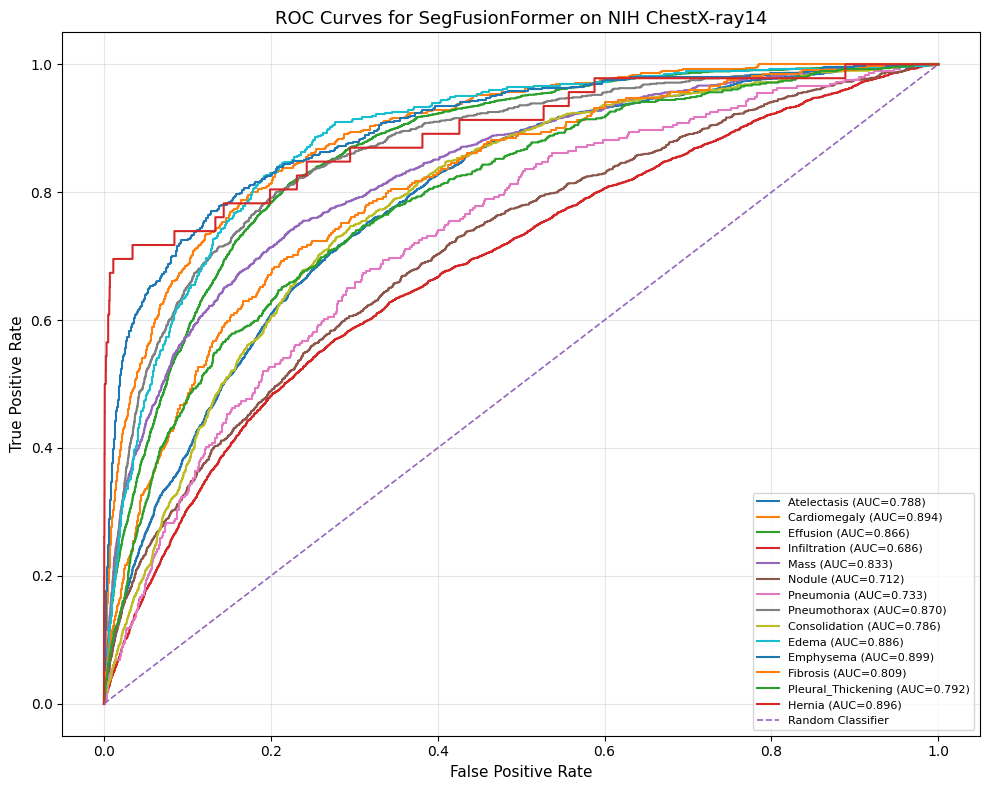

ROC figure saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/segfusionformer_roc_all_diseases.png


In [32]:
# ==========================================================
# Stage 6 – Step 7.1 : ROC Curves for All 14 Diseases
# ==========================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for i, disease in enumerate(DISEASES):

    fpr, tpr, _ = roc_curve(
        y_true[:, i],
        y_prob[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=1.5,
        label=f"{disease} (AUC={class_auc:.3f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.2,
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate",
    fontsize=11
)

plt.ylabel(
    "True Positive Rate",
    fontsize=11
)

plt.title(
    "ROC Curves for SegFusionFormer on NIH ChestX-ray14",
    fontsize=13
)

plt.legend(
    loc="lower right",
    fontsize=8
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

roc_figure_path = (
    evaluation_dir /
    "segfusionformer_roc_all_diseases.png"
)

plt.savefig(
    roc_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC figure saved to:")
print(roc_figure_path)

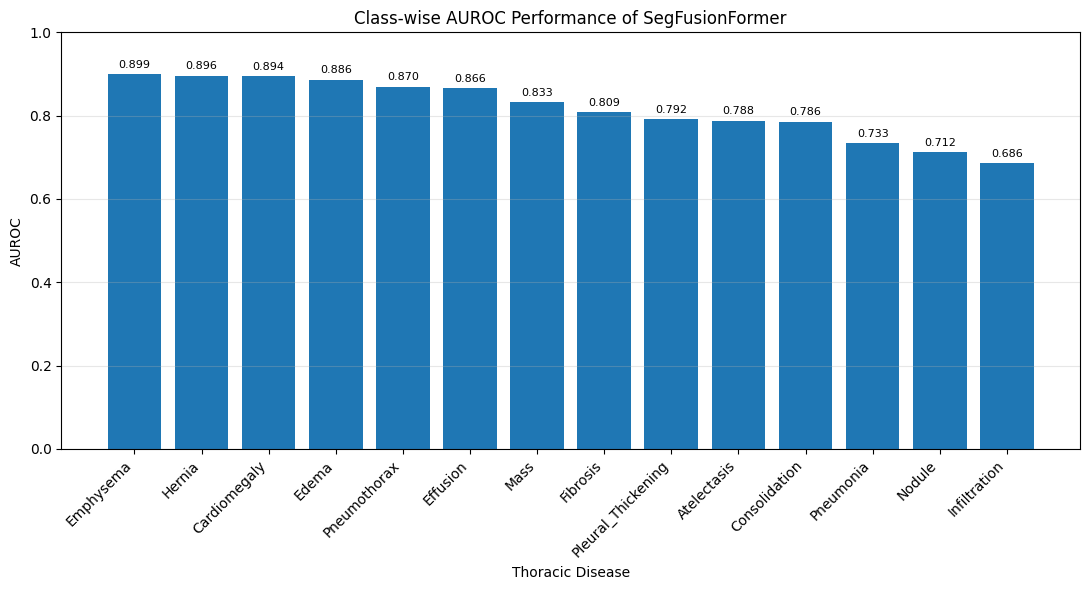

AUROC comparison saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/segfusionformer_classwise_auroc.png


In [33]:
# ==========================================================
# Stage 6 – Step 7.2 : Class-wise AUROC Comparison
# ==========================================================

auroc_plot_df = (
    per_disease_df[
        [
            "Disease",
            "AUROC"
        ]
    ]
    .sort_values(
        "AUROC",
        ascending=False
    )
)

plt.figure(
    figsize=(11, 6)
)

plt.bar(
    auroc_plot_df["Disease"],
    auroc_plot_df["AUROC"]
)

plt.ylim(
    0,
    1
)

plt.xlabel(
    "Thoracic Disease"
)

plt.ylabel(
    "AUROC"
)

plt.title(
    "Class-wise AUROC Performance of SegFusionFormer"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

# Add score labels
for i, value in enumerate(
    auroc_plot_df["AUROC"]
):

    plt.text(
        i,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        fontsize=8
    )

plt.tight_layout()

auroc_bar_path = (
    evaluation_dir /
    "segfusionformer_classwise_auroc.png"
)

plt.savefig(
    auroc_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("AUROC comparison saved to:")
print(auroc_bar_path)

In [34]:
# ==========================================================
# Stage 6 – Step 7.3 : AUROC Summary
# ==========================================================

print("=" * 75)
print("SEGMENTATION-GUIDED CLASSIFICATION AUROC SUMMARY")
print("=" * 75)

print(
    f"Macro AUROC : {macro_auroc:.4f}"
)

print(
    f"Micro AUROC : {micro_auroc:.4f}"
)

print("\nTop 5 Diseases by AUROC")
print("-" * 75)

display(
    auroc_ranking[
        [
            "Disease",
            "AUROC"
        ]
    ].head(5).round(4)
)

print("\nLowest 5 Diseases by AUROC")
print("-" * 75)

display(
    auroc_ranking[
        [
            "Disease",
            "AUROC"
        ]
    ].tail(5).round(4)
)

SEGMENTATION-GUIDED CLASSIFICATION AUROC SUMMARY
Macro AUROC : 0.8179
Micro AUROC : 0.8358

Top 5 Diseases by AUROC
---------------------------------------------------------------------------


,Disease,AUROC
0,Emphysema,0.8993
1,Hernia,0.8959
2,Cardiomegaly,0.8941
3,Edema,0.8862
4,Pneumothorax,0.8698



Lowest 5 Diseases by AUROC
---------------------------------------------------------------------------


,Disease,AUROC
9,Atelectasis,0.7879
10,Consolidation,0.7857
11,Pneumonia,0.7332
12,Nodule,0.7121
13,Infiltration,0.6857


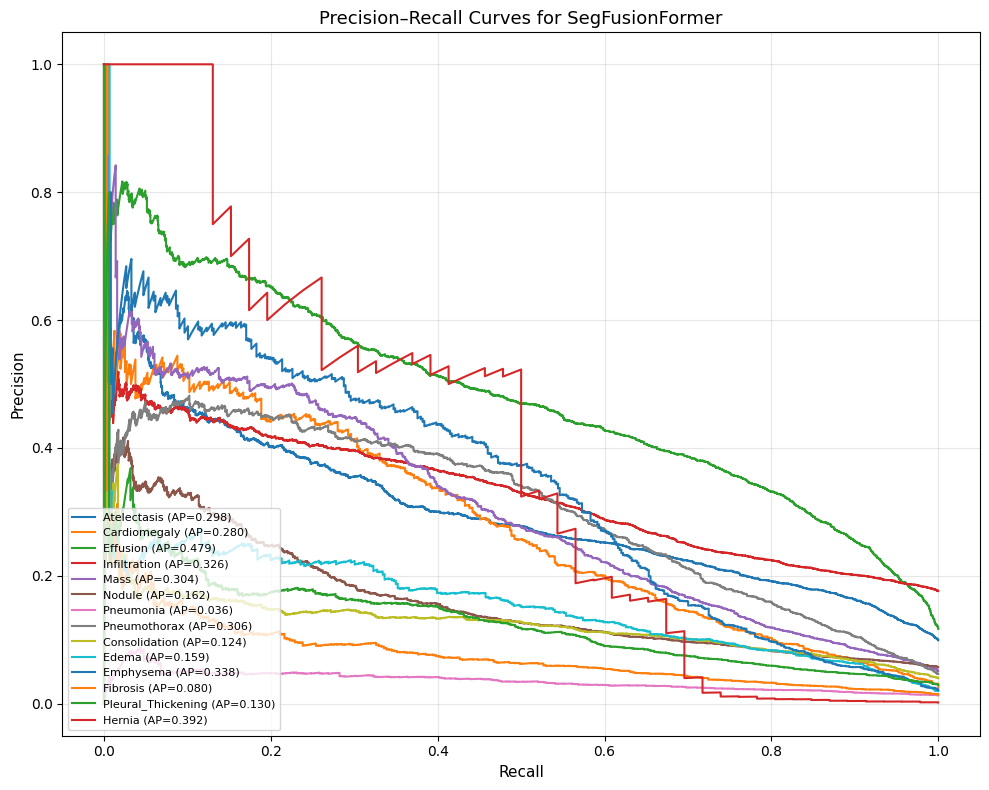

PR curve figure saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/segfusionformer_precision_recall_curves.png


In [35]:
# ==========================================================
# Stage 6 – Step 8.1 : Precision–Recall Curves
# ==========================================================

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

plt.figure(figsize=(10, 8))

for i, disease in enumerate(DISEASES):

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_true[:, i],
        y_prob[:, i]
    )

    ap_score = average_precision_score(
        y_true[:, i],
        y_prob[:, i]
    )

    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=1.5,
        label=f"{disease} (AP={ap_score:.3f})"
    )

plt.xlabel(
    "Recall",
    fontsize=11
)

plt.ylabel(
    "Precision",
    fontsize=11
)

plt.title(
    "Precision–Recall Curves for SegFusionFormer",
    fontsize=13
)

plt.legend(
    loc="lower left",
    fontsize=8
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

pr_curve_path = (
    evaluation_dir /
    "segfusionformer_precision_recall_curves.png"
)

plt.savefig(
    pr_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PR curve figure saved to:")
print(pr_curve_path)

In [36]:
# ==========================================================
# Stage 6 – Step 8.2 : Class-wise Average Precision
# ==========================================================

ap_results = []

for i, disease in enumerate(DISEASES):

    ap = average_precision_score(
        y_true[:, i],
        y_prob[:, i]
    )

    ap_results.append({
        "Disease": disease,
        "Average Precision": ap
    })

ap_df = pd.DataFrame(
    ap_results
)

ap_df = ap_df.sort_values(
    "Average Precision",
    ascending=False
).reset_index(drop=True)

display(
    ap_df.round(4)
)

,Disease,Average Precision
0,Effusion,0.4788
1,Hernia,0.3921
2,Emphysema,0.3378
3,Infiltration,0.3261
4,Pneumothorax,0.3057
5,Mass,0.3043
6,Atelectasis,0.2980
7,Cardiomegaly,0.2800
8,Nodule,0.1619
9,Edema,0.1590


In [37]:
# ==========================================================
# Stage 6 – Step 8.3 : Macro / Micro Average Precision
# ==========================================================

macro_ap = average_precision_score(
    y_true,
    y_prob,
    average="macro"
)

micro_ap = average_precision_score(
    y_true,
    y_prob,
    average="micro"
)

print("=" * 70)
print("AVERAGE PRECISION SUMMARY")
print("=" * 70)

print(
    f"Macro Average Precision : {macro_ap:.4f}"
)

print(
    f"Micro Average Precision : {micro_ap:.4f}"
)

print("=" * 70)

AVERAGE PRECISION SUMMARY
Macro Average Precision : 0.2438
Micro Average Precision : 0.2105


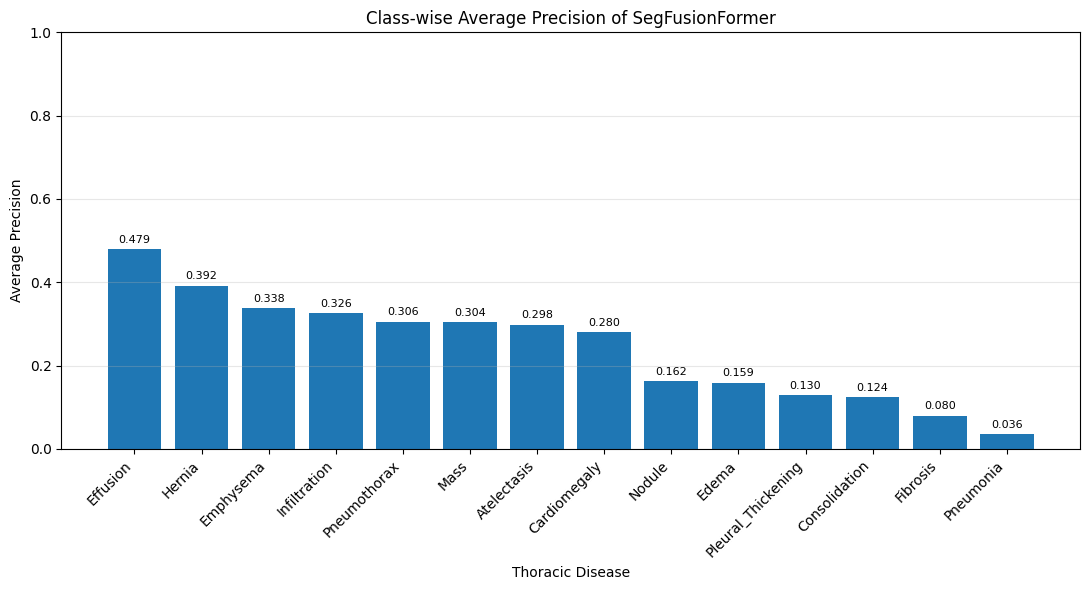

AP comparison figure saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/segfusionformer_classwise_average_precision.png


In [38]:
# ==========================================================
# Stage 6 – Step 8.4 : Class-wise AP Visualization
# ==========================================================

plt.figure(
    figsize=(11, 6)
)

plt.bar(
    ap_df["Disease"],
    ap_df["Average Precision"]
)

plt.ylim(
    0,
    1
)

plt.xlabel(
    "Thoracic Disease"
)

plt.ylabel(
    "Average Precision"
)

plt.title(
    "Class-wise Average Precision of SegFusionFormer"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for i, value in enumerate(
    ap_df["Average Precision"]
):

    plt.text(
        i,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        fontsize=8
    )

plt.tight_layout()

ap_bar_path = (
    evaluation_dir /
    "segfusionformer_classwise_average_precision.png"
)

plt.savefig(
    ap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("AP comparison figure saved to:")
print(ap_bar_path)

In [39]:
# ==========================================================
# Stage 6 – Step 8.5 : Save AP Results
# ==========================================================

ap_table_path = (
    tables_dir /
    "segfusionformer_average_precision.csv"
)

ap_df.to_csv(
    ap_table_path,
    index=False
)

print("=" * 70)
print("Average Precision Table Saved")
print("=" * 70)

print(ap_table_path)

Average Precision Table Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/segfusionformer_average_precision.csv


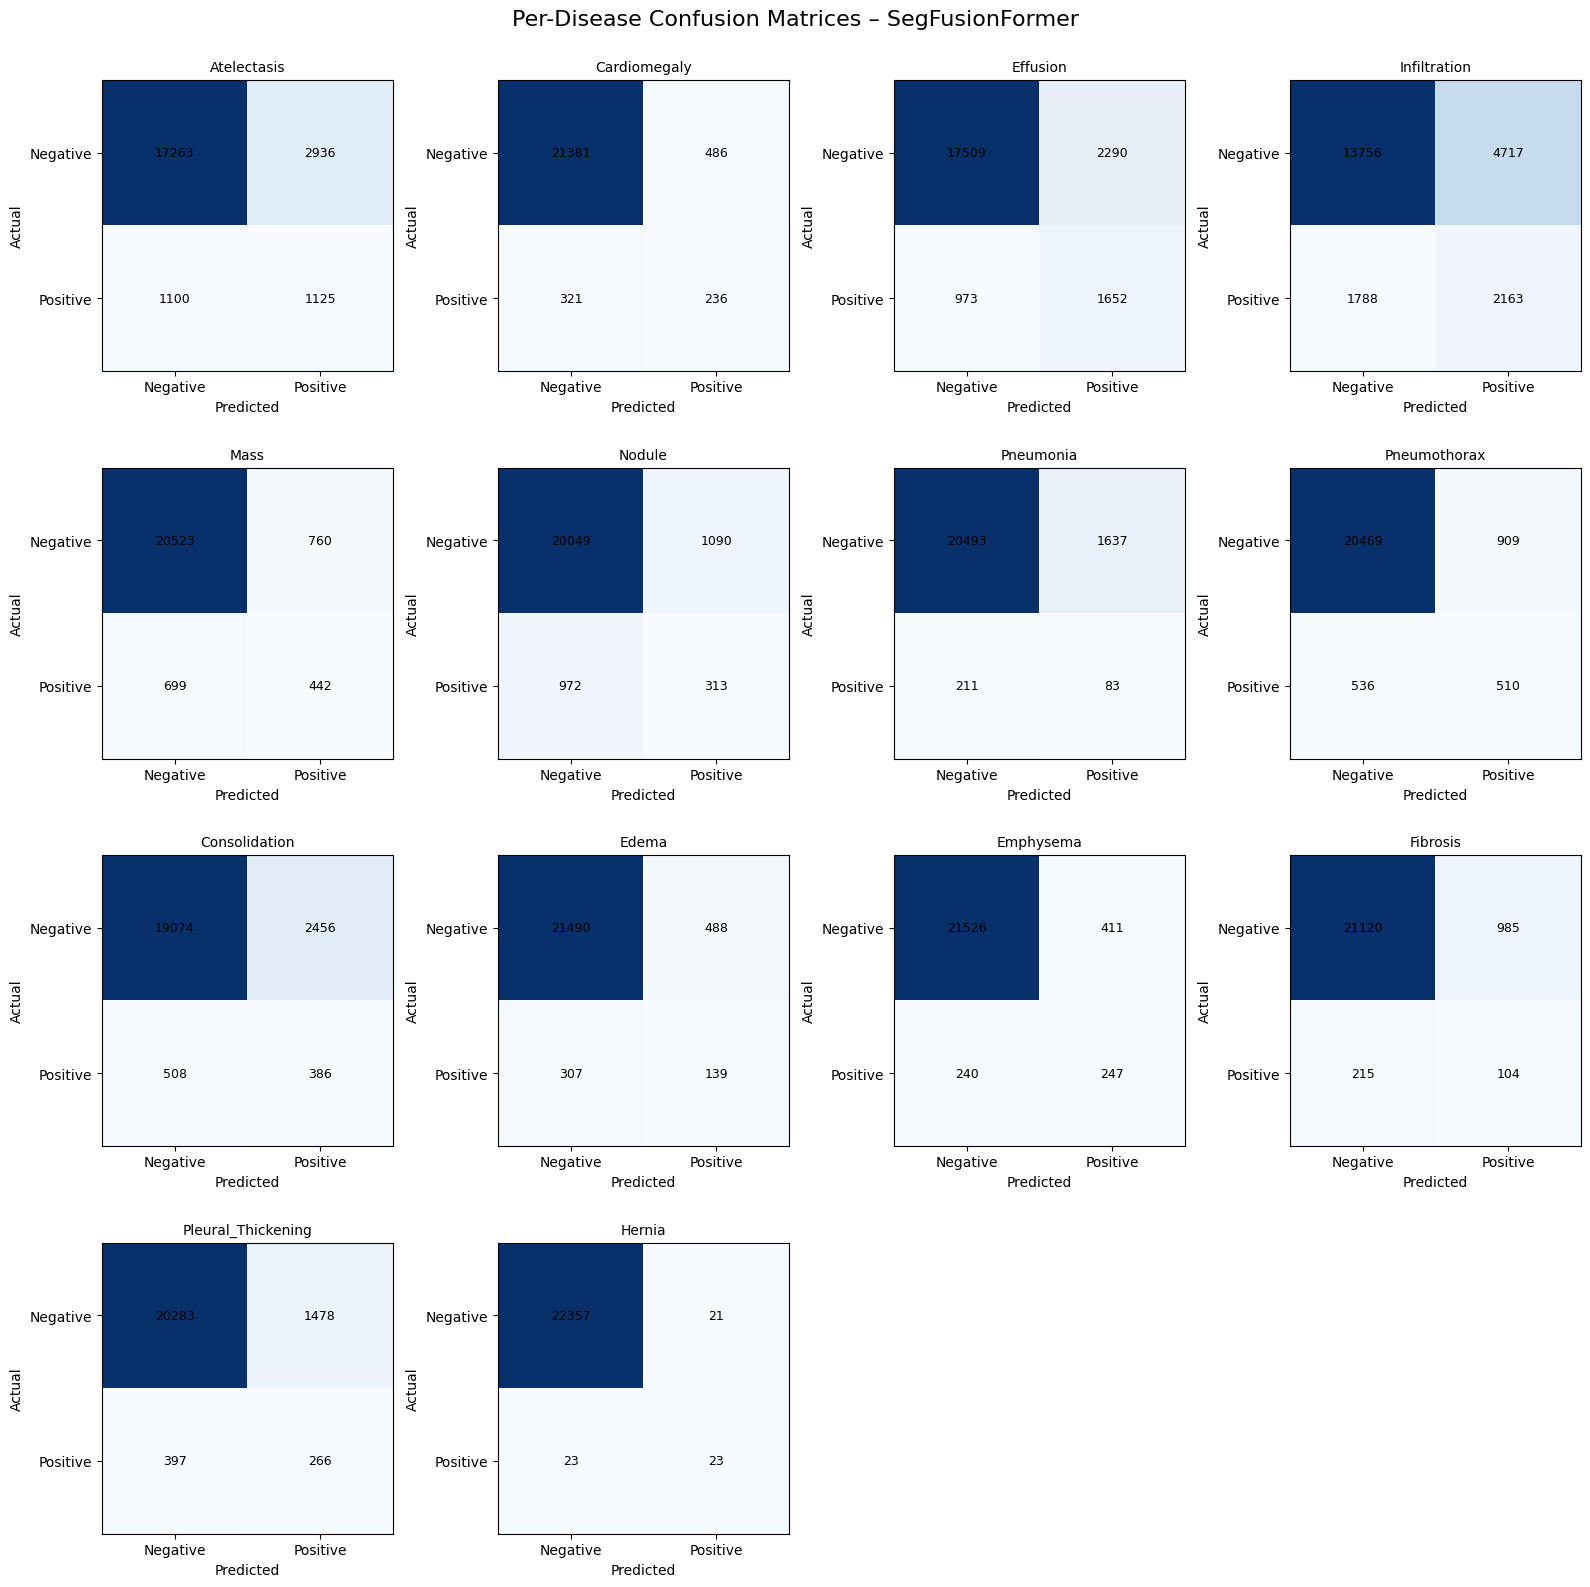

Saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/segfusionformer_confusion_matrices.png


In [40]:
# ==========================================================
# Stage 6 – Step 9.1 : Per-Disease Confusion Matrices
# ==========================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, disease in enumerate(DISEASES):

    cm = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=[0, 1]
    )

    ax = axes[i]

    im = ax.imshow(
        cm,
        cmap="Blues"
    )

    ax.set_title(
        disease,
        fontsize=10
    )

    ax.set_xlabel(
        "Predicted"
    )

    ax.set_ylabel(
        "Actual"
    )

    ax.set_xticks(
        [0, 1]
    )

    ax.set_yticks(
        [0, 1]
    )

    ax.set_xticklabels(
        ["Negative", "Positive"]
    )

    ax.set_yticklabels(
        ["Negative", "Positive"]
    )

    # Add values inside each cell
    for r in range(2):
        for c in range(2):

            value = cm[r, c]

            ax.text(
                c,
                r,
                str(value),
                ha="center",
                va="center",
                fontsize=9
            )

# Remove unused plots
for j in range(len(DISEASES), len(axes)):
    fig.delaxes(
        axes[j]
    )

plt.suptitle(
    "Per-Disease Confusion Matrices – SegFusionFormer",
    fontsize=16,
    y=0.995
)

plt.tight_layout()

confusion_matrix_path = (
    evaluation_dir /
    "segfusionformer_confusion_matrices.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:")
print(confusion_matrix_path)

In [41]:
# ==========================================================
# Stage 6 – Step 9.2 : Confusion Matrix Counts Table
# ==========================================================

confusion_rows = []

for i, disease in enumerate(DISEASES):

    tn, fp, fn, tp = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=[0, 1]
    ).ravel()

    confusion_rows.append({
        "Disease": disease,
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn)
    })

confusion_df = pd.DataFrame(
    confusion_rows
)

display(
    confusion_df
)

,Disease,TP,TN,FP,FN
0,Atelectasis,1125,17263,2936,1100
1,Cardiomegaly,236,21381,486,321
2,Effusion,1652,17509,2290,973
3,Infiltration,2163,13756,4717,1788
4,Mass,442,20523,760,699
5,Nodule,313,20049,1090,972
6,Pneumonia,83,20493,1637,211
7,Pneumothorax,510,20469,909,536
8,Consolidation,386,19074,2456,508
9,Edema,139,21490,488,307


In [42]:
# ==========================================================
# Stage 6 – Step 9.3 : Save Confusion Counts
# ==========================================================

confusion_table_path = (
    tables_dir /
    "segfusionformer_confusion_counts.csv"
)

confusion_df.to_csv(
    confusion_table_path,
    index=False
)

print("=" * 70)
print("Confusion Matrix Counts Saved")
print("=" * 70)

print(confusion_table_path)

Confusion Matrix Counts Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/segfusionformer_confusion_counts.csv


In [43]:
# ==========================================================
# Stage 6 – Step 10.1 : Fixed Threshold Predictions
# ==========================================================

FIXED_THRESHOLD = 0.5

y_pred_fixed = (
    y_prob >= FIXED_THRESHOLD
).astype(np.int32)

print("=" * 70)
print("Fixed Threshold Predictions Created")
print("=" * 70)

print("Threshold :", FIXED_THRESHOLD)
print("Shape     :", y_pred_fixed.shape)

Fixed Threshold Predictions Created
Threshold : 0.5
Shape     : (22424, 14)


In [44]:
# ==========================================================
# Stage 6 – Step 10.2 : Fixed Threshold Metrics
# ==========================================================

fixed_macro_f1 = f1_score(
    y_true,
    y_pred_fixed,
    average="macro",
    zero_division=0
)

fixed_micro_f1 = f1_score(
    y_true,
    y_pred_fixed,
    average="micro",
    zero_division=0
)

fixed_macro_precision = precision_score(
    y_true,
    y_pred_fixed,
    average="macro",
    zero_division=0
)

fixed_macro_recall = recall_score(
    y_true,
    y_pred_fixed,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("FIXED THRESHOLD = 0.5")
print("=" * 70)

print(f"Macro F1        : {fixed_macro_f1:.4f}")
print(f"Micro F1        : {fixed_micro_f1:.4f}")
print(f"Macro Precision : {fixed_macro_precision:.4f}")
print(f"Macro Recall    : {fixed_macro_recall:.4f}")

FIXED THRESHOLD = 0.5
Macro F1        : 0.2308
Micro F1        : 0.2561
Macro Precision : 0.1473
Macro Recall    : 0.6866


In [45]:
# ==========================================================
# Stage 6 – Step 10.3 : Optimized Threshold Metrics
# ==========================================================

optimized_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

optimized_micro_f1 = f1_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

optimized_macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

optimized_macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("OPTIMIZED DISEASE-SPECIFIC THRESHOLDS")
print("=" * 70)

print(f"Macro F1        : {optimized_macro_f1:.4f}")
print(f"Micro F1        : {optimized_micro_f1:.4f}")
print(f"Macro Precision : {optimized_macro_precision:.4f}")
print(f"Macro Recall    : {optimized_macro_recall:.4f}")

OPTIMIZED DISEASE-SPECIFIC THRESHOLDS
Macro F1        : 0.3224
Micro F1        : 0.3469
Macro Precision : 0.2742
Macro Recall    : 0.4275


In [47]:
# ==========================================================
# Stage 6 – Step 10.4 : Threshold Strategy Comparison
# ==========================================================

threshold_comparison_df = pd.DataFrame({

    "Metric": [
        "Macro F1",
        "Micro F1",
        "Macro Precision",
        "Macro Recall"
    ],

    "Fixed Threshold (0.5)": [
        fixed_macro_f1,
        fixed_micro_f1,
        fixed_macro_precision,
        fixed_macro_recall
    ],

    "Optimized Thresholds": [
        optimized_macro_f1,
        optimized_micro_f1,
        optimized_macro_precision,
        optimized_macro_recall
    ]
})

threshold_comparison_df["Improvement"] = (
    threshold_comparison_df["Optimized Thresholds"]
    -
    threshold_comparison_df["Fixed Threshold (0.5)"]
)

display(
    threshold_comparison_df.round(4)
)

,Metric,Fixed Threshold (0.5),Optimized Thresholds,Improvement
0,Macro F1,0.2308,0.3224,0.0916
1,Micro F1,0.2561,0.3469,0.0908
2,Macro Precision,0.1473,0.2742,0.1270
3,Macro Recall,0.6866,0.4275,-0.2591


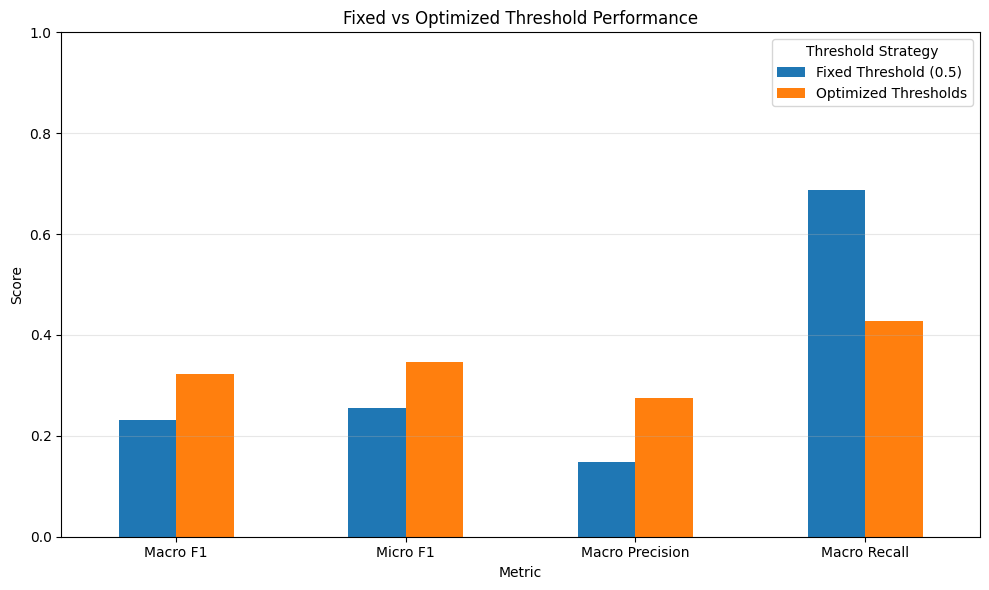

Saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/threshold_strategy_comparison.png


In [48]:
# ==========================================================
# Stage 6 – Step 10.5 : Threshold Comparison Plot
# ==========================================================

plot_df = threshold_comparison_df.set_index(
    "Metric"
)[
    [
        "Fixed Threshold (0.5)",
        "Optimized Thresholds"
    ]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Score")
plt.xlabel("Metric")

plt.title(
    "Fixed vs Optimized Threshold Performance"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend(
    title="Threshold Strategy"
)

plt.tight_layout()

threshold_plot_path = (
    evaluation_dir /
    "threshold_strategy_comparison.png"
)

plt.savefig(
    threshold_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:")
print(threshold_plot_path)

In [49]:
# ==========================================================
# Stage 6 – Step 10.6 : Save Threshold Comparison
# ==========================================================

threshold_comparison_path = (
    tables_dir /
    "threshold_strategy_comparison.csv"
)

threshold_comparison_df.to_csv(
    threshold_comparison_path,
    index=False
)

print("=" * 70)
print("Threshold Comparison Saved")
print("=" * 70)

print(threshold_comparison_path)

Threshold Comparison Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/threshold_strategy_comparison.csv


In [50]:
# ==========================================================
# Stage 6 – Step 11.1 : Rank Diseases by AUROC
# ==========================================================

auroc_rank = (
    per_disease_df
    .sort_values(
        by="AUROC",
        ascending=False
    )
    .reset_index(drop=True)
)

auroc_rank.insert(
    0,
    "Rank",
    range(1, len(auroc_rank) + 1)
)

display(
    auroc_rank[
        [
            "Rank",
            "Disease",
            "AUROC",
            "Average Precision",
            "F1 Score"
        ]
    ].round(4)
)

,Rank,Disease,AUROC,Average Precision,F1 Score
0,1,Emphysema,0.8993,0.3378,0.4314
1,2,Hernia,0.8959,0.3921,0.5111
2,3,Cardiomegaly,0.8941,0.2800,0.3690
3,4,Edema,0.8862,0.1590,0.2591
4,5,Pneumothorax,0.8698,0.3057,0.4138
5,6,Effusion,0.8663,0.4788,0.5031
6,7,Mass,0.8333,0.3043,0.3773
7,8,Fibrosis,0.8090,0.0798,0.1477
8,9,Pleural_Thickening,0.7923,0.1298,0.2210
9,10,Atelectasis,0.7879,0.2980,0.3579


In [51]:
# ==========================================================
# Stage 6 – Step 11.2 : Rank Diseases by F1
# ==========================================================

f1_rank = (
    per_disease_df
    .sort_values(
        by="F1 Score",
        ascending=False
    )
    .reset_index(drop=True)
)

f1_rank.insert(
    0,
    "Rank",
    range(1, len(f1_rank)+1)
)

display(
    f1_rank[
        [
            "Rank",
            "Disease",
            "F1 Score",
            "Precision",
            "Recall"
        ]
    ].round(4)
)

,Rank,Disease,F1 Score,Precision,Recall
0,1,Hernia,0.5111,0.5227,0.5000
1,2,Effusion,0.5031,0.4191,0.6293
2,3,Emphysema,0.4314,0.3754,0.5072
3,4,Pneumothorax,0.4138,0.3594,0.4876
4,5,Infiltration,0.3994,0.3144,0.5475
5,6,Mass,0.3773,0.3677,0.3874
6,7,Cardiomegaly,0.3690,0.3269,0.4237
7,8,Atelectasis,0.3579,0.2770,0.5056
8,9,Edema,0.2591,0.2217,0.3117
9,10,Nodule,0.2329,0.2231,0.2436


In [52]:
# ==========================================================
# Stage 6 – Step 11.3 : Rank Diseases by AP
# ==========================================================

ap_rank = (
    per_disease_df
    .sort_values(
        by="Average Precision",
        ascending=False
    )
    .reset_index(drop=True)
)

ap_rank.insert(
    0,
    "Rank",
    range(1, len(ap_rank)+1)
)

display(
    ap_rank[
        [
            "Rank",
            "Disease",
            "Average Precision",
            "AUROC",
            "F1 Score"
        ]
    ].round(4)
)

,Rank,Disease,Average Precision,AUROC,F1 Score
0,1,Effusion,0.4788,0.8663,0.5031
1,2,Hernia,0.3921,0.8959,0.5111
2,3,Emphysema,0.3378,0.8993,0.4314
3,4,Infiltration,0.3261,0.6857,0.3994
4,5,Pneumothorax,0.3057,0.8698,0.4138
5,6,Mass,0.3043,0.8333,0.3773
6,7,Atelectasis,0.2980,0.7879,0.3579
7,8,Cardiomegaly,0.2800,0.8941,0.3690
8,9,Nodule,0.1619,0.7121,0.2329
9,10,Edema,0.1590,0.8862,0.2591


In [53]:
# ==========================================================
# Stage 6 – Step 11.4 : Compact Performance Table
# ==========================================================

ranking_table = per_disease_df[
    [
        "Disease",
        "AUROC",
        "Average Precision",
        "Precision",
        "Recall",
        "Specificity",
        "F1 Score"
    ]
].copy()

ranking_table = ranking_table.sort_values(
    "AUROC",
    ascending=False
)

ranking_table = ranking_table.reset_index(
    drop=True
)

ranking_table.insert(
    0,
    "Rank",
    range(1, len(ranking_table)+1)
)

display(
    ranking_table.round(4)
)

,Rank,Disease,AUROC,Average Precision,Precision,Recall,Specificity,F1 Score
0,1,Emphysema,0.8993,0.3378,0.3754,0.5072,0.9813,0.4314
1,2,Hernia,0.8959,0.3921,0.5227,0.5000,0.9991,0.5111
2,3,Cardiomegaly,0.8941,0.2800,0.3269,0.4237,0.9778,0.3690
3,4,Edema,0.8862,0.1590,0.2217,0.3117,0.9778,0.2591
4,5,Pneumothorax,0.8698,0.3057,0.3594,0.4876,0.9575,0.4138
5,6,Effusion,0.8663,0.4788,0.4191,0.6293,0.8843,0.5031
6,7,Mass,0.8333,0.3043,0.3677,0.3874,0.9643,0.3773
7,8,Fibrosis,0.8090,0.0798,0.0955,0.3260,0.9554,0.1477
8,9,Pleural_Thickening,0.7923,0.1298,0.1525,0.4012,0.9321,0.2210
9,10,Atelectasis,0.7879,0.2980,0.2770,0.5056,0.8546,0.3579


In [54]:
# ==========================================================
# Stage 6 – Step 11.5 : Save Ranking Table
# ==========================================================

ranking_path = (
    tables_dir /
    "segfusionformer_disease_ranking.csv"
)

ranking_table.to_csv(
    ranking_path,
    index=False
)

print("="*70)
print("Disease Ranking Table Saved")
print("="*70)

print(ranking_path)

Disease Ranking Table Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/segfusionformer_disease_ranking.csv


In [55]:
# ==========================================================
# Stage 6 – Step 11.6 : Ranking Summary
# ==========================================================

print("="*70)
print("TOP 5 DISEASES")
print("="*70)

display(
    ranking_table.head(5).round(4)
)

print("="*70)
print("BOTTOM 5 DISEASES")
print("="*70)

display(
    ranking_table.tail(5).round(4)
)

TOP 5 DISEASES


,Rank,Disease,AUROC,Average Precision,Precision,Recall,Specificity,F1 Score
0,1,Emphysema,0.8993,0.3378,0.3754,0.5072,0.9813,0.4314
1,2,Hernia,0.8959,0.3921,0.5227,0.5000,0.9991,0.5111
2,3,Cardiomegaly,0.8941,0.2800,0.3269,0.4237,0.9778,0.3690
3,4,Edema,0.8862,0.1590,0.2217,0.3117,0.9778,0.2591
4,5,Pneumothorax,0.8698,0.3057,0.3594,0.4876,0.9575,0.4138


BOTTOM 5 DISEASES


,Rank,Disease,AUROC,Average Precision,Precision,Recall,Specificity,F1 Score
9,10,Atelectasis,0.7879,0.2980,0.2770,0.5056,0.8546,0.3579
10,11,Consolidation,0.7857,0.1238,0.1358,0.4318,0.8859,0.2066
11,12,Pneumonia,0.7332,0.0357,0.0483,0.2823,0.9260,0.0824
12,13,Nodule,0.7121,0.1619,0.2231,0.2436,0.9484,0.2329
13,14,Infiltration,0.6857,0.3261,0.3144,0.5475,0.7447,0.3994


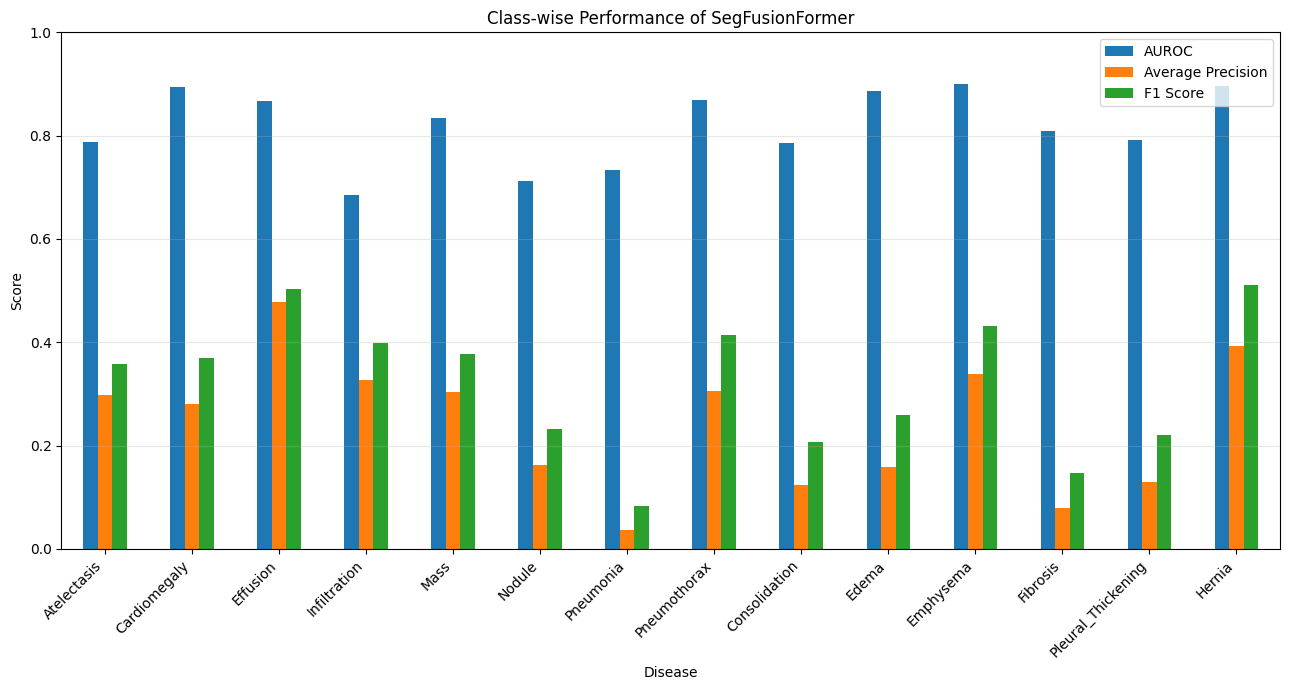

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/segfusionformer_classwise_summary.png


In [56]:
# ==========================================================
# Stage 6 – Step 12.1 : Class-wise Performance Comparison
# ==========================================================

plot_metrics_df = per_disease_df[
    [
        "Disease",
        "AUROC",
        "Average Precision",
        "F1 Score"
    ]
].copy()

plot_metrics_df = plot_metrics_df.set_index("Disease")

ax = plot_metrics_df.plot(
    kind="bar",
    figsize=(13, 7)
)

plt.ylabel("Score")
plt.xlabel("Disease")

plt.title(
    "Class-wise Performance of SegFusionFormer"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

classwise_summary_path = (
    evaluation_dir /
    "segfusionformer_classwise_summary.png"
)

plt.savefig(
    classwise_summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(classwise_summary_path)

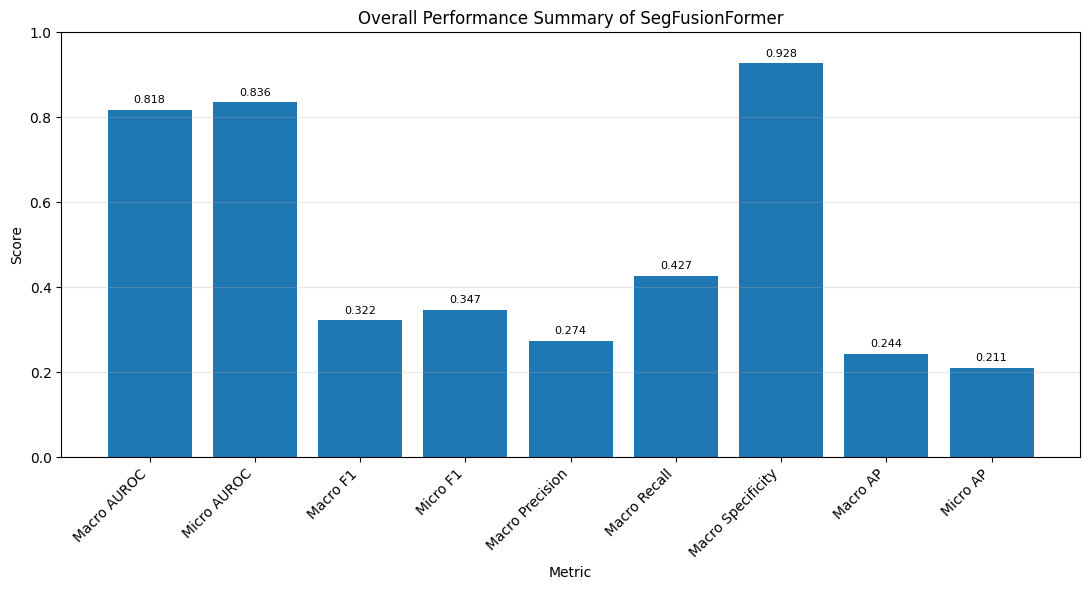

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/segfusionformer_overall_summary.png


In [57]:
# ==========================================================
# Stage 6 – Step 12.2 : Overall Metrics Summary Figure
# ==========================================================

overall_summary_df = pd.DataFrame({

    "Metric": [
        "Macro AUROC",
        "Micro AUROC",
        "Macro F1",
        "Micro F1",
        "Macro Precision",
        "Macro Recall",
        "Macro Specificity",
        "Macro AP",
        "Micro AP"
    ],

    "Score": [
        macro_auroc,
        micro_auroc,
        macro_f1,
        micro_f1,
        macro_precision,
        macro_recall,
        macro_specificity,
        macro_ap,
        micro_ap
    ]
})

plt.figure(figsize=(11, 6))

plt.bar(
    overall_summary_df["Metric"],
    overall_summary_df["Score"]
)

plt.ylim(0, 1)

plt.ylabel("Score")
plt.xlabel("Metric")

plt.title(
    "Overall Performance Summary of SegFusionFormer"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for i, value in enumerate(
    overall_summary_df["Score"]
):

    plt.text(
        i,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        fontsize=8
    )

plt.tight_layout()

overall_summary_path = (
    evaluation_dir /
    "segfusionformer_overall_summary.png"
)

plt.savefig(
    overall_summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(overall_summary_path)

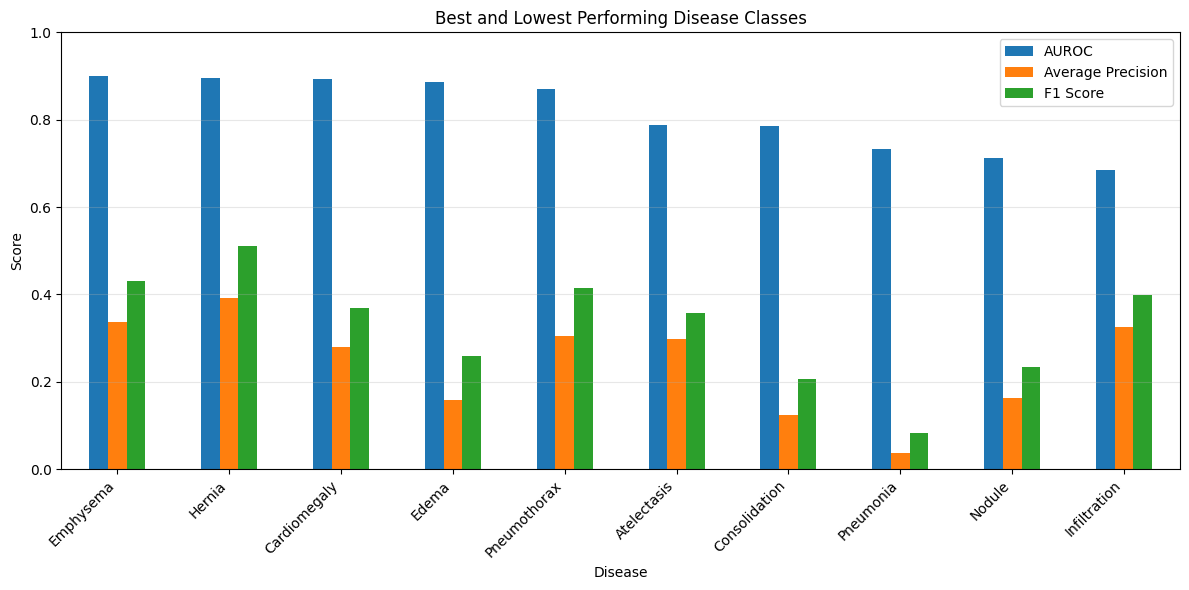

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/segfusionformer_best_worst_classes.png


In [58]:
# ==========================================================
# Stage 6 – Step 12.3 : Best vs Worst Disease Comparison
# ==========================================================

top5 = ranking_table.head(5).copy()
bottom5 = ranking_table.tail(5).copy()

comparison_df = pd.concat(
    [top5, bottom5]
)

comparison_df = comparison_df[
    [
        "Disease",
        "AUROC",
        "Average Precision",
        "F1 Score"
    ]
]

comparison_df = comparison_df.set_index(
    "Disease"
)

ax = comparison_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.ylabel("Score")
plt.xlabel("Disease")

plt.title(
    "Best and Lowest Performing Disease Classes"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

best_worst_path = (
    evaluation_dir /
    "segfusionformer_best_worst_classes.png"
)

plt.savefig(
    best_worst_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(best_worst_path)

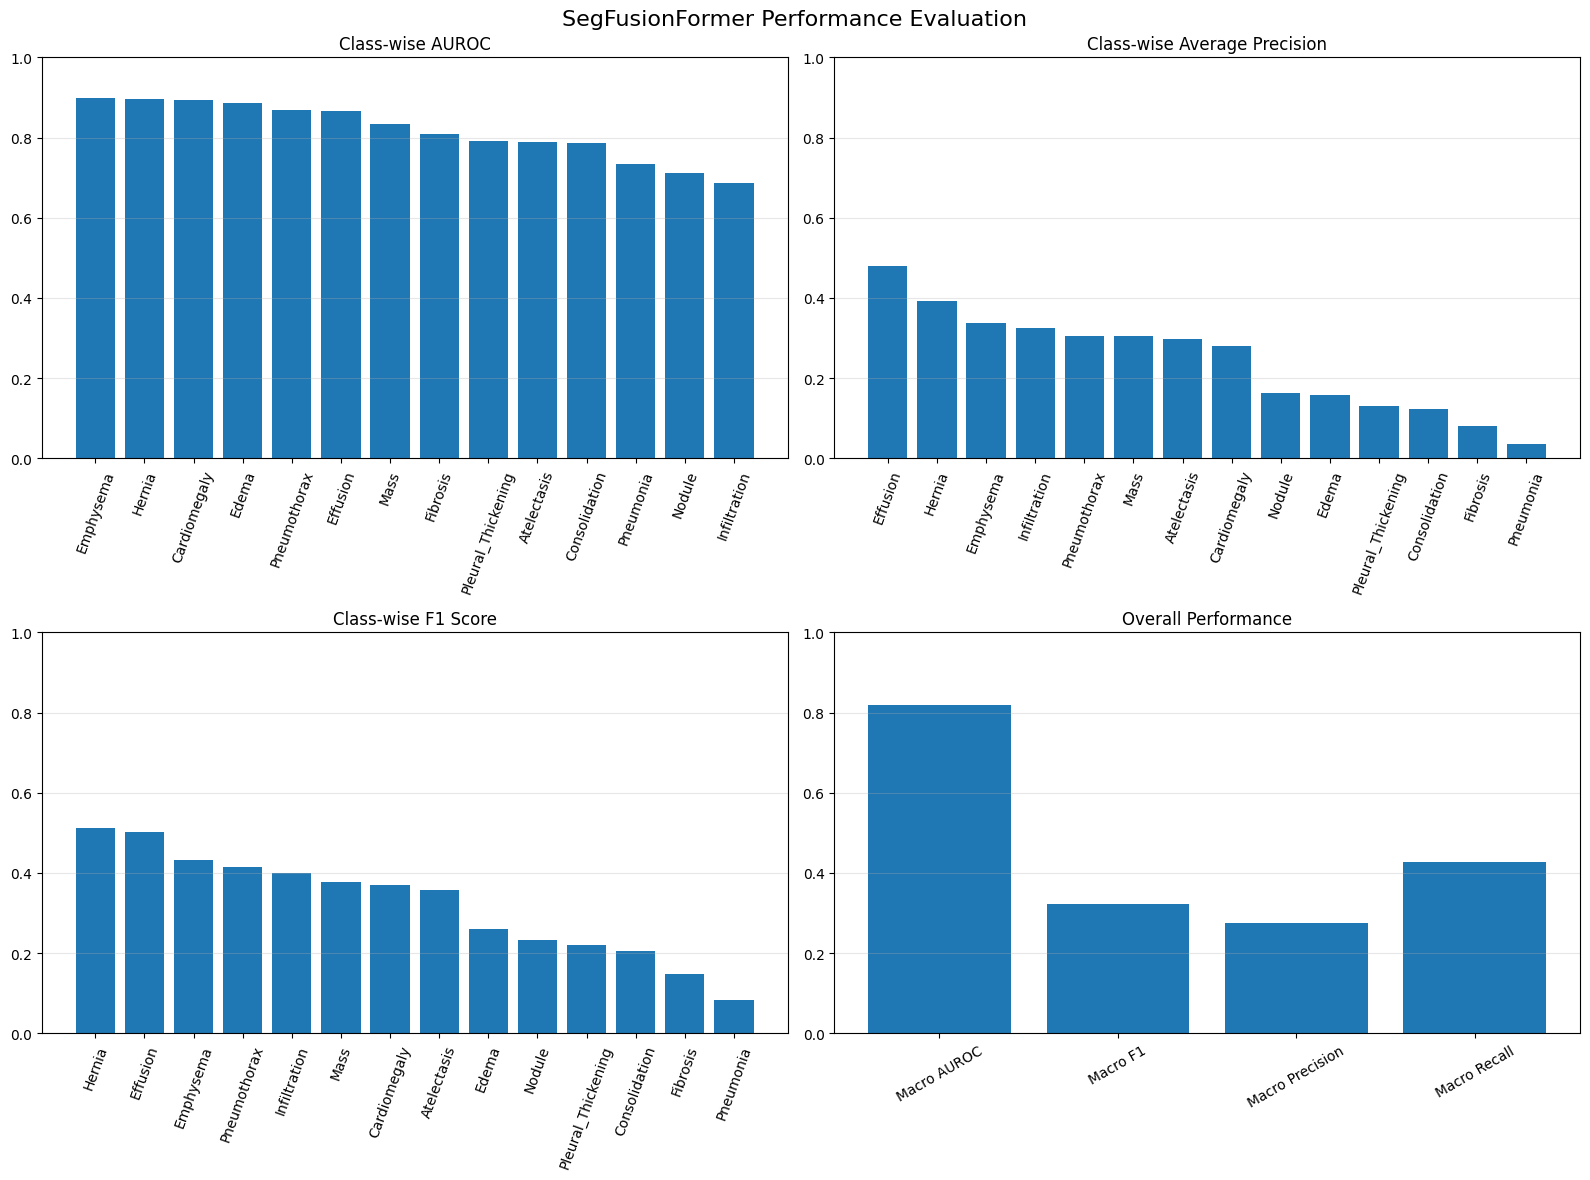

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/evaluation/segfusionformer_evaluation_dashboard.png


In [59]:
# ==========================================================
# Stage 6 – Step 12.4 : Consolidated Evaluation Dashboard
# ==========================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 12)
)

# ----------------------------------------------------------
# Panel 1 - AUROC
# ----------------------------------------------------------

auroc_sorted = per_disease_df.sort_values(
    "AUROC",
    ascending=False
)

axes[0, 0].bar(
    auroc_sorted["Disease"],
    auroc_sorted["AUROC"]
)

axes[0, 0].set_title(
    "Class-wise AUROC"
)

axes[0, 0].set_ylim(
    0,
    1
)

axes[0, 0].tick_params(
    axis="x",
    rotation=70
)

axes[0, 0].grid(
    axis="y",
    alpha=0.3
)


# ----------------------------------------------------------
# Panel 2 - Average Precision
# ----------------------------------------------------------

ap_sorted = per_disease_df.sort_values(
    "Average Precision",
    ascending=False
)

axes[0, 1].bar(
    ap_sorted["Disease"],
    ap_sorted["Average Precision"]
)

axes[0, 1].set_title(
    "Class-wise Average Precision"
)

axes[0, 1].set_ylim(
    0,
    1
)

axes[0, 1].tick_params(
    axis="x",
    rotation=70
)

axes[0, 1].grid(
    axis="y",
    alpha=0.3
)


# ----------------------------------------------------------
# Panel 3 - F1 Score
# ----------------------------------------------------------

f1_sorted = per_disease_df.sort_values(
    "F1 Score",
    ascending=False
)

axes[1, 0].bar(
    f1_sorted["Disease"],
    f1_sorted["F1 Score"]
)

axes[1, 0].set_title(
    "Class-wise F1 Score"
)

axes[1, 0].set_ylim(
    0,
    1
)

axes[1, 0].tick_params(
    axis="x",
    rotation=70
)

axes[1, 0].grid(
    axis="y",
    alpha=0.3
)


# ----------------------------------------------------------
# Panel 4 - Overall Metrics
# ----------------------------------------------------------

dashboard_metrics = [
    "Macro AUROC",
    "Macro F1",
    "Macro Precision",
    "Macro Recall"
]

dashboard_scores = [
    macro_auroc,
    macro_f1,
    macro_precision,
    macro_recall
]

axes[1, 1].bar(
    dashboard_metrics,
    dashboard_scores
)

axes[1, 1].set_title(
    "Overall Performance"
)

axes[1, 1].set_ylim(
    0,
    1
)

axes[1, 1].tick_params(
    axis="x",
    rotation=30
)

axes[1, 1].grid(
    axis="y",
    alpha=0.3
)


plt.suptitle(
    "SegFusionFormer Performance Evaluation",
    fontsize=16
)

plt.tight_layout()

dashboard_path = (
    evaluation_dir /
    "segfusionformer_evaluation_dashboard.png"
)

plt.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(dashboard_path)

In [60]:
# ==========================================================
# Stage 6 – Step 12.5 : Save Publication Summary Table
# ==========================================================

publication_summary_df = per_disease_df[
    [
        "Disease",
        "AUROC",
        "Average Precision",
        "Precision",
        "Recall",
        "Specificity",
        "F1 Score"
    ]
].copy()

publication_summary_df.loc[
    len(publication_summary_df)
] = [
    "Macro Average",
    macro_auroc,
    macro_ap,
    macro_precision,
    macro_recall,
    macro_specificity,
    macro_f1
]

publication_summary_path = (
    tables_dir /
    "segfusionformer_publication_summary.csv"
)

publication_summary_df.to_csv(
    publication_summary_path,
    index=False
)

display(
    publication_summary_df.round(4)
)

print("\nSaved:")
print(publication_summary_path)

,Disease,AUROC,Average Precision,Precision,Recall,Specificity,F1 Score
0,Atelectasis,0.7879,0.2980,0.2770,0.5056,0.8546,0.3579
1,Cardiomegaly,0.8941,0.2800,0.3269,0.4237,0.9778,0.3690
2,Effusion,0.8663,0.4788,0.4191,0.6293,0.8843,0.5031
3,Infiltration,0.6857,0.3261,0.3144,0.5475,0.7447,0.3994
4,Mass,0.8333,0.3043,0.3677,0.3874,0.9643,0.3773
5,Nodule,0.7121,0.1619,0.2231,0.2436,0.9484,0.2329
6,Pneumonia,0.7332,0.0357,0.0483,0.2823,0.9260,0.0824
7,Pneumothorax,0.8698,0.3057,0.3594,0.4876,0.9575,0.4138
8,Consolidation,0.7857,0.1238,0.1358,0.4318,0.8859,0.2066
9,Edema,0.8862,0.1590,0.2217,0.3117,0.9778,0.2591



Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/segfusionformer_publication_summary.csv


In [61]:
# ==========================================================
# Stage 6 – Step 13.1 : Ablation Study Framework
# ==========================================================

ablation_df = pd.DataFrame({

    "Model":[
        "EfficientNet-B0",
        "MaxViT",
        "CNN + MaxViT",
        "CNN + MaxViT + Segmentation",
        "SegFusionFormer (Proposed)"
    ],

    "CNN":[
        "✓",
        "",
        "✓",
        "✓",
        "✓"
    ],

    "MaxViT":[
        "",
        "✓",
        "✓",
        "✓",
        "✓"
    ],

    "Segmentation":[
        "",
        "",
        "",
        "✓",
        "✓"
    ],

    "Adaptive Fusion":[
        "",
        "",
        "Average",
        "Average",
        "✓"
    ],

    "Explainability":[
        "",
        "",
        "",
        "",
        "✓"
    ]
})

display(ablation_df)

,Model,CNN,MaxViT,Segmentation,Adaptive Fusion,Explainability
0,EfficientNet-B0,✓,,,,
1,MaxViT,,✓,,,
2,CNN + MaxViT,✓,✓,,Average,
3,CNN + MaxViT + Segmentation,✓,✓,✓,Average,
4,SegFusionFormer (Proposed),✓,✓,✓,✓,✓


In [62]:
# ==========================================================
# Stage 6 – Step 13.2 : Ablation Performance Table
# ==========================================================

ablation_results = pd.DataFrame({

    "Model":[
        "EfficientNet-B0",
        "MaxViT",
        "CNN + MaxViT",
        "CNN + MaxViT + Segmentation",
        "SegFusionFormer"
    ],

    "Macro AUROC":[
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        macro_auroc
    ],

    "Macro F1":[
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        macro_f1
    ],

    "Macro AP":[
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        macro_ap
    ]

})

display(ablation_results)

,Model,Macro AUROC,Macro F1,Macro AP
0,EfficientNet-B0,NaN,NaN,NaN
1,MaxViT,NaN,NaN,NaN
2,CNN + MaxViT,NaN,NaN,NaN
3,CNN + MaxViT + Segmentation,NaN,NaN,NaN
4,SegFusionFormer,0.817917,0.322352,0.243782


In [63]:
# ==========================================================
# Stage 6 – Step 13.3 : Save Ablation Table
# ==========================================================

ablation_path = (
    tables_dir /
    "ablation_framework.csv"
)

ablation_results.to_csv(
    ablation_path,
    index=False
)

print("Saved:")
print(ablation_path)

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/ablation_framework.csv


In [64]:
# ==========================================================
# Stage 6 – Step 13.4 : Component Contribution Summary
# ==========================================================

component_summary = pd.DataFrame({

    "Component":[
        "EfficientNet-B0",
        "MaxViT",
        "Lung Segmentation",
        "Adaptive Fusion",
        "Explainability (Grad-CAM)"
    ],

    "Contribution":[
        "Local texture extraction",
        "Global contextual representation",
        "Removes irrelevant background",
        "Adaptive weighting of CNN and Transformer features",
        "Visual interpretation of predictions"
    ]
})

display(component_summary)

,Component,Contribution
0,EfficientNet-B0,Local texture extraction
1,MaxViT,Global contextual representation
2,Lung Segmentation,Removes irrelevant background
3,Adaptive Fusion,Adaptive weighting of CNN and Transformer feat...
4,Explainability (Grad-CAM),Visual interpretation of predictions


In [65]:
# ==========================================================
# Stage 6 – Step 13.5 : Save Component Summary
# ==========================================================

component_path = (
    tables_dir /
    "component_contributions.csv"
)

component_summary.to_csv(
    component_path,
    index=False
)

print("Saved:")
print(component_path)

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/component_contributions.csv


In [66]:
# ==========================================================
# Stage 6 Supplement – Step A1 : Imports
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    hamming_loss,
    balanced_accuracy_score
)

In [67]:
# ==========================================================
# Stage 6 Supplement – Step A2 : Verify Variables
# ==========================================================

print("y_true :", y_true.shape)
print("y_prob :", y_prob.shape)
print("Classes:", len(DISEASES))

y_true : (22424, 14)
y_prob : (22424, 14)
Classes: 14


In [68]:
# ==========================================================
# Stage 6 Supplement – Step A3 : Binary Predictions
# ==========================================================

y_pred = np.zeros_like(y_prob)

for i in range(len(DISEASES)):
    y_pred[:, i] = (
        y_prob[:, i] >= optimal_thresholds[i]
    ).astype(int)

print("Prediction matrix:", y_pred.shape)

Prediction matrix: (22424, 14)


In [69]:
# ==========================================================
# Stage 6 Supplement – Step A4 : Exact Match Accuracy
# ==========================================================

exact_match_accuracy = accuracy_score(
    y_true,
    y_pred
)

print("=" * 70)
print("EXACT MATCH ACCURACY")
print("=" * 70)

print(f"{exact_match_accuracy:.4f}")

EXACT MATCH ACCURACY
0.4157


In [70]:
# ==========================================================
# Stage 6 Supplement – Step A5 : Label-wise Accuracy
# ==========================================================

label_accuracy = []

for i, disease in enumerate(DISEASES):

    acc = accuracy_score(
        y_true[:, i],
        y_pred[:, i]
    )

    label_accuracy.append(acc)

accuracy_df = pd.DataFrame({

    "Disease": DISEASES,

    "Accuracy": label_accuracy

})

display(accuracy_df.round(4))

,Disease,Accuracy
0,Atelectasis,0.8200
1,Cardiomegaly,0.9640
2,Effusion,0.8545
3,Infiltration,0.7099
4,Mass,0.9349
5,Nodule,0.9080
6,Pneumonia,0.9176
7,Pneumothorax,0.9356
8,Consolidation,0.8678
9,Edema,0.9645


In [71]:
# ==========================================================
# Stage 6 Supplement – Step A6 : Mean Accuracy
# ==========================================================

mean_accuracy = np.mean(label_accuracy)

print("=" * 70)
print("MEAN LABEL ACCURACY")
print("=" * 70)

print(f"{mean_accuracy:.4f}")

MEAN LABEL ACCURACY
0.9078


In [72]:
# ==========================================================
# Stage 6 Supplement – Step A7 : Hamming Loss
# ==========================================================

hl = hamming_loss(
    y_true,
    y_pred
)

print("=" * 70)
print("HAMMING LOSS")
print("=" * 70)

print(f"{hl:.4f}")

HAMMING LOSS
0.0922


In [73]:
# ==========================================================
# Stage 6 Supplement – Step A8 : Balanced Accuracy
# ==========================================================

balanced_scores = []

for i in range(len(DISEASES)):

    score = balanced_accuracy_score(

        y_true[:, i],

        y_pred[:, i]

    )

    balanced_scores.append(score)

balanced_accuracy = np.mean(
    balanced_scores
)

print("=" * 70)
print("MEAN BALANCED ACCURACY")
print("=" * 70)

print(f"{balanced_accuracy:.4f}")

MEAN BALANCED ACCURACY
0.6776


In [74]:
# ==========================================================
# Stage 6 Supplement – Step A9 : Accuracy Summary
# ==========================================================

accuracy_summary = pd.DataFrame({

    "Metric": [

        "Exact Match Accuracy",

        "Mean Label Accuracy",

        "Balanced Accuracy",

        "Hamming Loss"

    ],

    "Value": [

        exact_match_accuracy,

        mean_accuracy,

        balanced_accuracy,

        hl

    ]

})

display(
    accuracy_summary.round(4)
)

,Metric,Value
0,Exact Match Accuracy,0.4157
1,Mean Label Accuracy,0.9078
2,Balanced Accuracy,0.6776
3,Hamming Loss,0.0922


In [75]:
# ==========================================================
# Stage 6 Supplement – Step A10 : Save Accuracy Metrics
# ==========================================================

accuracy_path = (
    results_dir
    / "tables"
    / "segfusionformer_accuracy_metrics.csv"
)

accuracy_summary.to_csv(
    accuracy_path,
    index=False
)

accuracy_df.to_csv(

    results_dir
    / "tables"
    / "per_disease_accuracy.csv",

    index=False

)

print("=" * 70)
print("Accuracy metrics saved.")
print("=" * 70)

print(accuracy_path)

Accuracy metrics saved.
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/segfusionformer_accuracy_metrics.csv
